# Hoja de Trabajo #2 — Transformers y Mecanismos de Atención

**CC3092 Deep Learning y Sistemas Inteligentes**

Parte 1: primitivas de atención en PyTorch (scaled dot-product, `nn.MultiheadAttention`, máscaras, codificación posicional).
Parte 2: visualización y análisis de la atención en **BERT** (`bert-base-uncased`) y **GPT-2** (`gpt2`): mapas de calor,
correferencia, atención causal, *attention sinks* y entropía por capa.

## 0. Imports y configuración

In [1]:
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_printoptions(precision=4, sci_mode=False, linewidth=120)
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10})

# Parte 1 — Atención en PyTorch

## 1.1 Scaled dot-product attention paso a paso

`Attention(Q, K, V) = softmax(Q Kᵀ / √d_k) V`. La división por `√d_k` mantiene la varianza de los productos punto en ~1:
si las componentes de `q` y `k` son independientes con media 0 y varianza 1, `q·k` tiene varianza `d_k`, y sin escalar
el softmax se satura (gradientes casi nulos). Ejemplo manual con 3 tokens y `d_k = 4`:

In [2]:
Q = torch.tensor([[1., 0., 1., 0.],
                  [0., 2., 0., 2.],
                  [1., 1., 0., 0.]])
K = torch.tensor([[1., 0., 0., 1.],
                  [0., 1., 1., 0.],
                  [1., 1., 1., 1.]])
V = torch.tensor([[1., 0., 0.],
                  [0., 2., 0.],
                  [0., 0., 3.]])
dk = Q.shape[-1]

S = Q @ K.T                      # 1) scores crudos
S_scaled = S / math.sqrt(dk)     # 2) escalar por sqrt(d_k) = 2
A = torch.softmax(S_scaled, -1)  # 3) softmax por fila
out = A @ V                      # 4) promedio ponderado de V
for n, t in [("Q Kᵀ", S), ("Q Kᵀ / √d_k", S_scaled), ("A = softmax(·)", A), ("A V", out)]:
    print(f"{n}:\n{t}\n")

ref = F.scaled_dot_product_attention(Q[None], K[None], V[None])[0]
assert torch.allclose(out, ref, atol=1e-6), "no coincide con F.scaled_dot_product_attention"
print("OK: coincide con F.scaled_dot_product_attention;  filas de A suman", A.sum(-1))

Q Kᵀ:
tensor([[1., 1., 2.],
        [2., 2., 4.],
        [1., 1., 2.]])

Q Kᵀ / √d_k:
tensor([[0.5000, 0.5000, 1.0000],
        [1.0000, 1.0000, 2.0000],
        [0.5000, 0.5000, 1.0000]])

A = softmax(·):
tensor([[0.2741, 0.2741, 0.4519],
        [0.2119, 0.2119, 0.5761],
        [0.2741, 0.2741, 0.4519]])

A V:
tensor([[0.2741, 0.5481, 1.3556],
        [0.2119, 0.4239, 1.7284],
        [0.2741, 0.5481, 1.3556]])

OK: coincide con F.scaled_dot_product_attention;  filas de A suman tensor([1., 1., 1.])


In [3]:
# Con máscara causal: el token i solo atiende a j <= i
T = Q.shape[0]
causal = torch.tril(torch.ones(T, T, dtype=torch.bool))
A_c = torch.softmax(S_scaled.masked_fill(~causal, float("-inf")), -1)
ref_c = F.scaled_dot_product_attention(Q[None], K[None], V[None], is_causal=True)[0]
assert torch.allclose(A_c @ V, ref_c, atol=1e-6)
print("A causal:\n", A_c)

A causal:
 tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.2741, 0.2741, 0.4519]])


## 1.2 `nn.MultiheadAttention`

Cada cabeza proyecta `x` a su propio subespacio (`d_k = d_model / h`), atiende en paralelo y las salidas se concatenan y
proyectan con `W_O`. Se verifica contra una implementación manual a partir de `in_proj_weight`.

In [4]:
d_model, h, T = 8, 2, 5
mha = nn.MultiheadAttention(d_model, h, batch_first=True).eval()
x = torch.randn(1, T, d_model)
with torch.no_grad():
    out, w = mha(x, x, x, need_weights=True, average_attn_weights=False)
print("salida:", tuple(out.shape), "| pesos por cabeza:", tuple(w.shape), "(batch, heads, T, T)")

# --- manual
Wq, Wk, Wv = mha.in_proj_weight.chunk(3)
bq, bk, bv = mha.in_proj_bias.chunk(3)
q, k, v = (x[0] @ Wq.T + bq), (x[0] @ Wk.T + bk), (x[0] @ Wv.T + bv)
split = lambda t: t.view(T, h, d_model // h).transpose(0, 1)       # (h, T, d_k)
qh, kh, vh = split(q), split(k), split(v)
att = torch.softmax(qh @ kh.transpose(-1, -2) / math.sqrt(d_model // h), -1)  # (h, T, T)
cat = (att @ vh).transpose(0, 1).reshape(T, d_model)                           # concatenar cabezas
manual = cat @ mha.out_proj.weight.T + mha.out_proj.bias
assert torch.allclose(att, w[0], atol=1e-5) and torch.allclose(manual, out[0], atol=1e-5)
print("OK: pesos y salida coinciden con la implementación manual")

salida: (1, 5, 8) | pesos por cabeza: (1, 2, 5, 5) (batch, heads, T, T)
OK: pesos y salida coinciden con la implementación manual


## 1.3 Máscaras

`nn.Transformer.generate_square_subsequent_mask(n)` devuelve una máscara **aditiva** (`-inf` sobre la diagonal, `0` en el resto).
Se suma a los scores antes del softmax. Un `key_padding_mask` booleano (`True` = ignorar) anula los tokens de relleno.

tensor([[0., -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0.]])
OK: peso 0 sobre posiciones futuras (causal) y sobre relleno (padding)


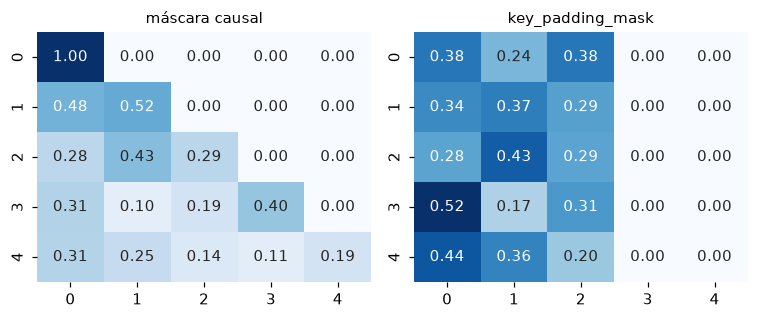

In [5]:
m = nn.Transformer.generate_square_subsequent_mask(5)
print(m)
with torch.no_grad():
    _, w_mask = mha(x, x, x, attn_mask=m, need_weights=True, average_attn_weights=False)
    pad = torch.tensor([[False, False, False, True, True]])      # últimos 2 tokens son relleno
    _, w_pad = mha(x, x, x, key_padding_mask=pad, need_weights=True, average_attn_weights=False)
assert torch.triu(w_mask[0, 0], diagonal=1).abs().max() == 0
assert w_pad[0, :, :, 3:].abs().max() == 0
print("OK: peso 0 sobre posiciones futuras (causal) y sobre relleno (padding)")
fig, axs = plt.subplots(1, 2, figsize=(7, 3))
sns.heatmap(w_mask[0, 0], ax=axs[0], cmap="Blues", cbar=False, annot=True, fmt=".2f"); axs[0].set_title("máscara causal")
sns.heatmap(w_pad[0, 0], ax=axs[1], cmap="Blues", cbar=False, annot=True, fmt=".2f"); axs[1].set_title("key_padding_mask")
plt.tight_layout(); plt.savefig("masks.png", dpi=150); plt.show()

## 1.4 Codificación posicional: sinusoidal vs RoPE

**Sinusoidal** (Vaswani et al.): `PE(pos, 2i) = sin(pos / 10000^{2i/d})`, `PE(pos, 2i+1) = cos(·)`; se **suma** al embedding.
**RoPE** (Su et al., 2021): se **rota** cada par de dimensiones de `q` y `k` un ángulo `pos·θ_i`; el producto `q_m · k_n`
depende solo de la posición relativa `m − n`.

q_m·k_n con m-n = 2: {(3, 1): -6.36248, (10, 8): -6.36248, (103, 101): -6.36248}
OK: el producto depende solo de m-n;  sin RoPE (3,1) vs (10,8): -4.361624240875244 (constante, ignora posición)


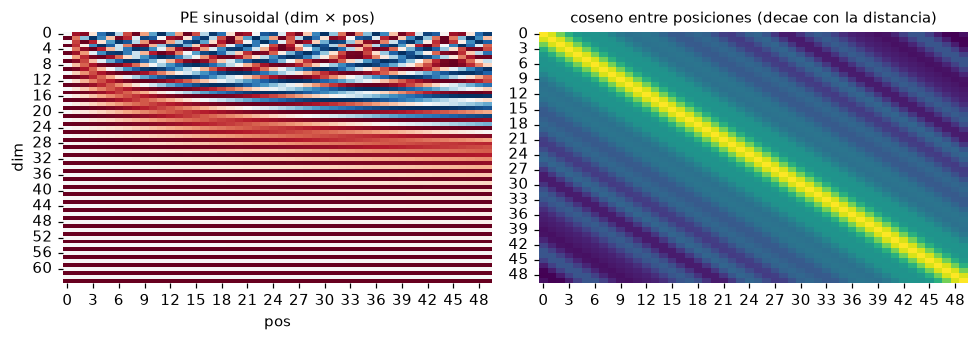

In [6]:
def sinusoidal_pe(T, d):
    pos = torch.arange(T)[:, None]
    i = torch.arange(0, d, 2)[None]
    pe = torch.zeros(T, d)
    pe[:, 0::2] = torch.sin(pos / 10000 ** (i / d)); pe[:, 1::2] = torch.cos(pos / 10000 ** (i / d))
    return pe

def rope(x, pos, base=10000.0):
    """x: (d,) con d par; rota cada par (x_{2i}, x_{2i+1}) por pos * base^{-2i/d}."""
    d = x.shape[-1]
    ang = pos * base ** (-torch.arange(0, d, 2) / d)
    c, s = torch.cos(ang), torch.sin(ang)
    x1, x2 = x[0::2], x[1::2]
    out = torch.empty_like(x); out[0::2] = x1 * c - x2 * s; out[1::2] = x1 * s + x2 * c
    return out

q0, k0 = torch.randn(64), torch.randn(64)
dots = {(m, n): float(rope(q0, m) @ rope(k0, n)) for m, n in [(3, 1), (10, 8), (103, 101)]}
print("q_m·k_n con m-n = 2:", {k: round(v, 5) for k, v in dots.items()})
assert max(dots.values()) - min(dots.values()) < 1e-4
print("OK: el producto depende solo de m-n;  sin RoPE (3,1) vs (10,8):", float(q0 @ k0), "(constante, ignora posición)")

pe = sinusoidal_pe(50, 64)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
sns.heatmap(pe.T, ax=axs[0], cmap="RdBu_r", center=0, cbar=False); axs[0].set(title="PE sinusoidal (dim × pos)", xlabel="pos", ylabel="dim")
sim = F.normalize(pe, dim=1) @ F.normalize(pe, dim=1).T
sns.heatmap(sim, ax=axs[1], cmap="viridis", cbar=False); axs[1].set(title="coseno entre posiciones (decae con la distancia)")
plt.tight_layout(); plt.savefig("posenc.png", dpi=150); plt.show()

# Parte 2 — Atención en BERT y GPT-2

Se cargan los modelos con `attn_implementation="eager"` y `output_attentions=True` (la implementación SDPA fusionada
no devuelve los pesos). `get_attn` devuelve un tensor `(capas, cabezas, T, T)`: ambos modelos tienen 12 capas × 12 cabezas.

In [7]:
from transformers import AutoTokenizer, AutoModel
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

def load(name):
    tok = AutoTokenizer.from_pretrained(name)
    model = AutoModel.from_pretrained(name, attn_implementation="eager", output_attentions=True).eval()
    return tok, model

@torch.no_grad()
def get_attn(tok, model, text):
    enc = tok(text, return_tensors="pt")
    A = torch.stack(model(**enc).attentions)[:, 0]          # (L, H, T, T)
    return A, tok.convert_ids_to_tokens(enc["input_ids"][0])

bert_tok, bert = load("bert-base-uncased")
gpt_tok, gpt = load("gpt2")
A, toks = get_attn(bert_tok, bert, "The animal didn't cross the street because it was too tired.")
print("BERT:", tuple(A.shape), toks)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

BERT: (12, 12, 16, 16) ['[CLS]', 'the', 'animal', 'didn', "'", 't', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']


## 2.1 Mapas de calor de BERT por capa y cabeza

Filas = token que atiende (*query*), columnas = token atendido (*key*). Cada fila suma 1. Se muestran 4 cabezas de las
capas 1, 6 y 12.

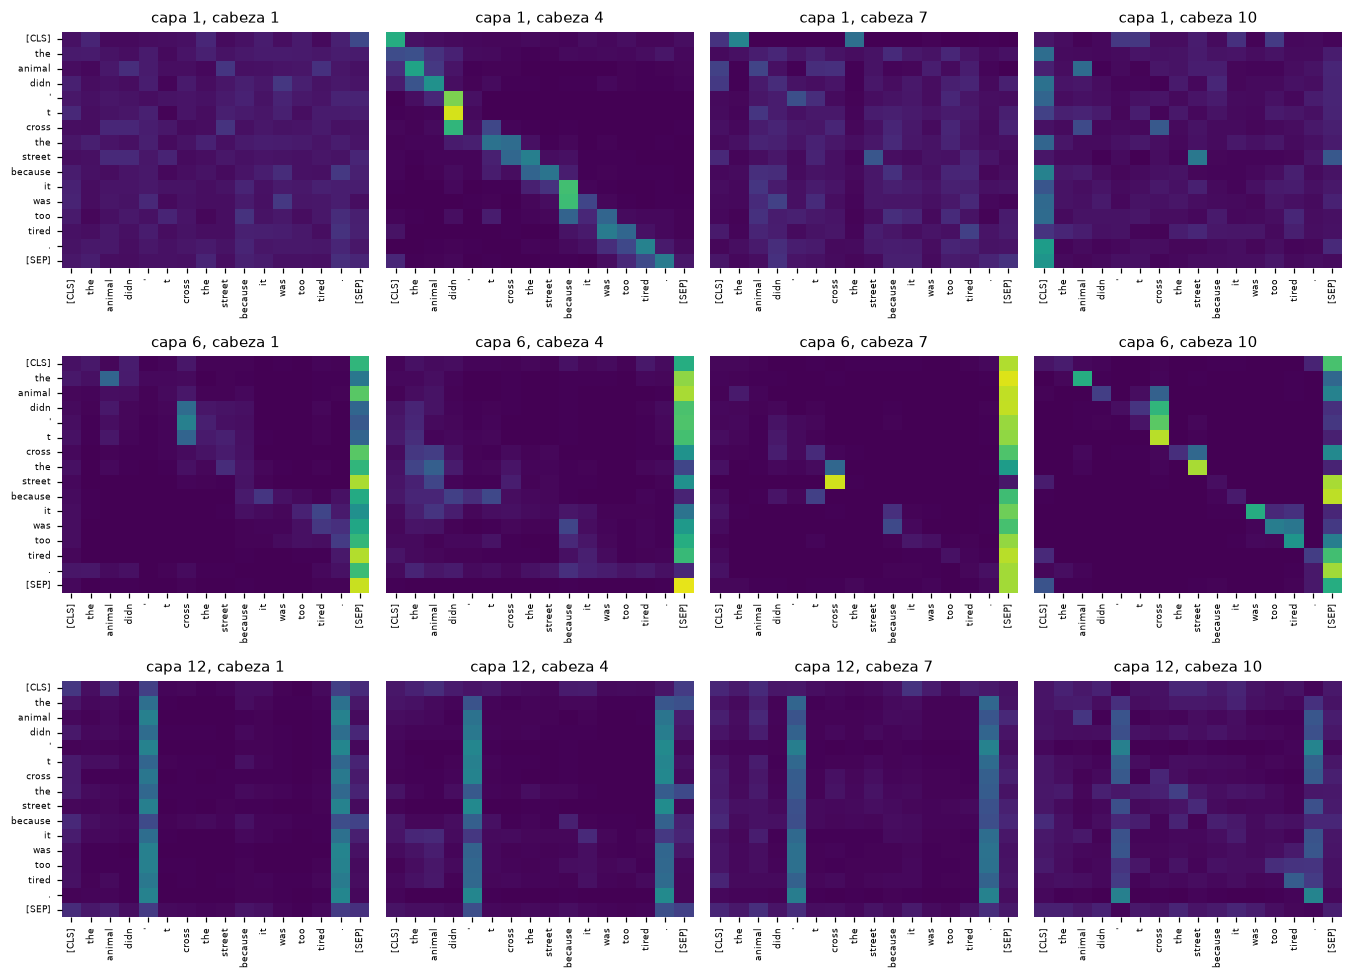

In [8]:
def plot_heads(A, toks, layers, heads, fname=None, cmap="viridis"):
    fig, axs = plt.subplots(len(layers), len(heads), figsize=(3.1 * len(heads), 3.0 * len(layers)), squeeze=False)
    for i, l in enumerate(layers):
        for j, h in enumerate(heads):
            ax = axs[i, j]
            sns.heatmap(A[l, h].numpy(), ax=ax, cmap=cmap, cbar=False, vmin=0, vmax=1,
                        xticklabels=toks, yticklabels=toks if j == 0 else False)
            ax.set_title(f"capa {l+1}, cabeza {h+1}")
            ax.tick_params(labelsize=6)
    plt.tight_layout()
    if fname: plt.savefig(fname, dpi=130)
    plt.show()

plot_heads(A, toks, layers=[0, 5, 11], heads=[0, 3, 6, 9], fname="bert_heatmaps.png")

In [9]:
# Patrones cuantificados: masa de atención en [CLS]/[SEP], en el token anterior y en el siguiente (media sobre cabezas)
def pattern_stats(A, toks):
    T = len(toks)
    special = torch.tensor([t in ("[CLS]", "[SEP]") for t in toks])
    prev = torch.stack([A[:, :, i, i - 1] for i in range(1, T)], -1).mean(-1)       # (L, H)
    nxt = torch.stack([A[:, :, i, i + 1] for i in range(T - 1)], -1).mean(-1)
    return pd.DataFrame({"capa": range(1, A.shape[0] + 1),
                         "[CLS]/[SEP]": A[..., special].sum(-1).mean((1, 2)).numpy(),
                         "token previo (media)": prev.mean(1).numpy(), "token previo (cabeza max)": prev.max(1).values.numpy(),
                         "token siguiente (media)": nxt.mean(1).numpy(), "token siguiente (cabeza max)": nxt.max(1).values.numpy()}).set_index("capa")

pattern_stats(A, toks).round(3)

,[CLS]/[SEP],token previo (media),token previo (cabeza max),token siguiente (media),token siguiente (cabeza max)
capa,,,,,
1,0.210,0.130,0.470,0.097,0.485
2,0.508,0.096,0.520,0.071,0.444
3,0.483,0.049,0.217,0.192,0.934
4,0.500,0.090,0.568,0.083,0.322
5,0.601,0.036,0.099,0.071,0.181
6,0.631,0.039,0.199,0.096,0.371
7,0.587,0.072,0.351,0.070,0.181
8,0.562,0.074,0.417,0.091,0.209
9,0.575,0.032,0.055,0.070,0.092


**Observaciones.** En capas intermedias/altas gran parte de la masa se concentra en `[CLS]`/`[SEP]` (tokens "de reposo" para
cabezas sin nada útil que hacer, ver Clark et al., 2019) y existen cabezas casi puramente posicionales (token previo / siguiente),
sobre todo en capas tempranas. La atención de BERT es bidireccional: la matriz no es triangular.

## 2.2 Resolución de correferencia

*"The animal didn't cross the street because it was too **tired**/**wide**."* El pronombre `it` se refiere a *animal* en la primera
y a *street* en la segunda. Para cada cabeza se mide, entre los dos candidatos, la fracción de atención de `it` que va a *animal*:
`r = A[it→animal] / (A[it→animal] + A[it→street])`. Una cabeza "resuelve" la correferencia si `r > 0.5` con *tired* y `r < 0.5` con *wide*.
Como `r` es una razón, se vuelve ruido si la cabeza casi no mira a ninguno de los dos candidatos; solo se consideran cabezas con
≥ 5% de masa sobre *animal* + *street* en ambas frases (en gris en el mapa las descartadas).

In [10]:
s_tired = "The animal didn't cross the street because it was too tired."
s_wide = "The animal didn't cross the street because it was too wide."

def coref_ratio(sentence):
    A, toks = get_attn(bert_tok, bert, sentence)
    it, an, st = toks.index("it"), toks.index("animal"), toks.index("street")
    a, s = A[:, :, it, an], A[:, :, it, st]
    return a / (a + s), a + s, A, toks, (it, an, st)

r_t, m_t, A_t, toks_t, idx = coref_ratio(s_tired)
r_w, m_w, A_w, toks_w, _ = coref_ratio(s_wide)
# r es ruidoso si la cabeza casi no mira a ninguno de los dos candidatos: exigir masa >= 5% sobre animal+street en ambas frases
elig = torch.minimum(m_t, m_w) >= 0.05
flip = (r_t > 0.5) & (r_w < 0.5) & elig
print(f"cabezas con masa suficiente sobre los candidatos: {int(elig.sum())}/144")
print(f"  de ellas, resuelven en ambos sentidos (r>0.5 con tired y r<0.5 con wide): {int(flip.sum())}  [azar ~25% = {elig.sum()/4:.0f}]")
print(f"media r (tired) = {r_t[elig].mean():.3f} | media r (wide) = {r_w[elig].mean():.3f}  (0.5 = sin preferencia)")
print("por capa, cabezas que resuelven:", flip.sum(1).tolist())

diff = (r_t - r_w)
score = torch.where(elig, diff, torch.full_like(diff, -9))   # ranking solo entre cabezas elegibles
top = [(int(l) + 1, int(h) + 1) for l, h in zip(*np.unravel_index(np.argsort(-score.numpy(), axis=None)[:5], diff.shape))]
print("top-5 (capa, cabeza) por r_tired - r_wide:", top, [round(float(diff[l-1, h-1]), 3) for l, h in top])

cabezas con masa suficiente sobre los candidatos: 61/144
  de ellas, resuelven en ambos sentidos (r>0.5 con tired y r<0.5 con wide): 14  [azar ~25% = 15]
media r (tired) = 0.712 | media r (wide) = 0.531  (0.5 = sin preferencia)
por capa, cabezas que resuelven: [0, 0, 0, 0, 1, 0, 3, 0, 4, 1, 1, 4]
top-5 (capa, cabeza) por r_tired - r_wide: [(7, 11), (9, 5), (9, 2), (9, 4), (12, 9)] [0.789, 0.762, 0.749, 0.687, 0.671]


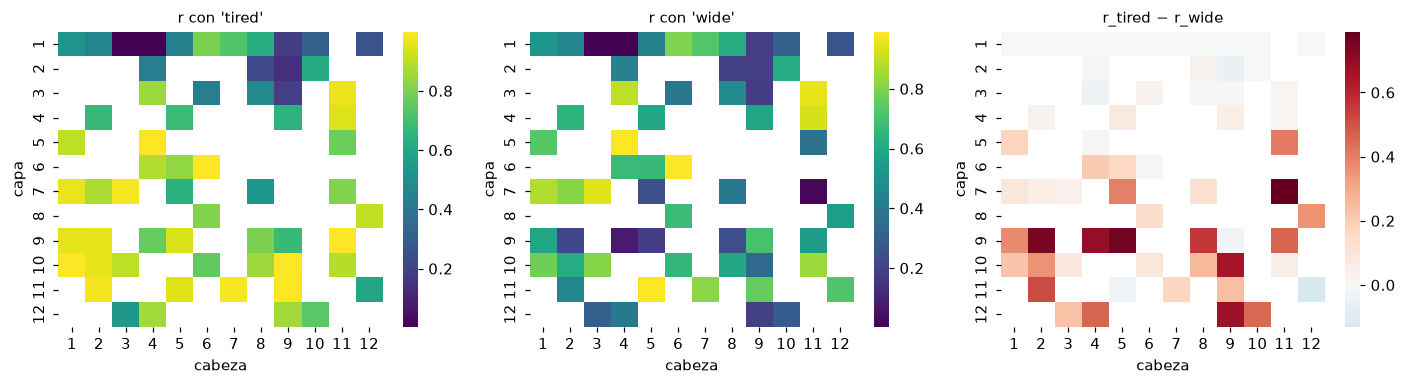

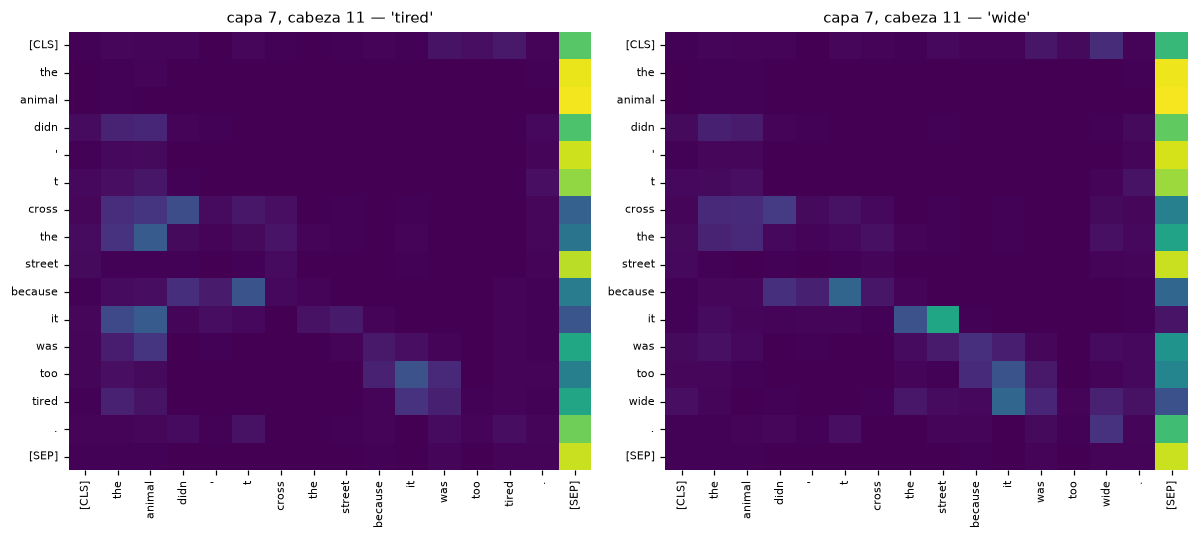

it→animal / it→street en esa cabeza: tired 0.284/0.067 | wide 0.012/0.590


In [11]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, M, t in [(axs[0], r_t, "r con 'tired'"), (axs[1], r_w, "r con 'wide'"), (axs[2], diff, "r_tired − r_wide")]:
    sns.heatmap(M.masked_fill(~elig, float("nan")).numpy(), ax=ax, cmap="RdBu_r" if M is diff else "viridis", center=0 if M is diff else None,
                xticklabels=range(1, 13), yticklabels=range(1, 13), cbar=True)
    ax.set(title=t, xlabel="cabeza", ylabel="capa")
plt.tight_layout(); plt.savefig("bert_coref_matrix.png", dpi=150); plt.show()

l, h = top[0][0] - 1, top[0][1] - 1
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
for ax, A_, tk, name in [(axs[0], A_t, toks_t, "tired"), (axs[1], A_w, toks_w, "wide")]:
    sns.heatmap(A_[l, h].numpy(), ax=ax, cmap="viridis", cbar=False, xticklabels=tk, yticklabels=tk, vmin=0, vmax=1)
    ax.set_title(f"capa {l+1}, cabeza {h+1} — '{name}'"); ax.tick_params(labelsize=7)
plt.tight_layout(); plt.savefig("bert_coref_head.png", dpi=150); plt.show()
print(f"it→animal / it→street en esa cabeza: tired {A_t[l,h,idx[0],idx[1]]:.3f}/{A_t[l,h,idx[0],idx[2]]:.3f} | "
      f"wide {A_w[l,h,idx[0],idx[1]]:.3f}/{A_w[l,h,idx[0],idx[2]]:.3f}")

**Lectura.** A nivel agregado el efecto es débil: de 61 cabezas con masa suficiente, 14 (23%) resuelven en ambos sentidos, lo mismo que
esperaría el azar (~25%), y se concentran en capas 7–12. Sin embargo, algunas cabezas separan claramente los casos (capa 7 cabeza 11:
con *tired* `it→animal` 0.28 vs `it→street` 0.07; con *wide* 0.01 vs 0.59). Dos cautelas: (i) escoger la mejor de 61 cabezas sobre un solo
par de oraciones es selección (comparaciones múltiples), no evidencia de que esa cabeza "haga correferencia"; (ii) la atención solo
muestra de dónde se lee información, no que el modelo use ese resultado (ver discusión sobre interpretabilidad).